### **Student Details**
- **Name:** Adarsh Shivanand Madli
- **SRN:** `PES2UG24CS028`
- **Course:** UE24CS342AA9 — Visualization of Data and User Interfaces (VDUI)
- **Unit:** Unit 3 — PPT 7: Interactive Visualization, Visual Analytics and Sensemaking

---
# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

Top 5 (city, day) cells with the most confirmed fraud:
     city  day  confirmed_fraud
     Pune   19               17
     Pune   18               13
     Pune   20               10
Bengaluru   15                4
Bengaluru   24                3


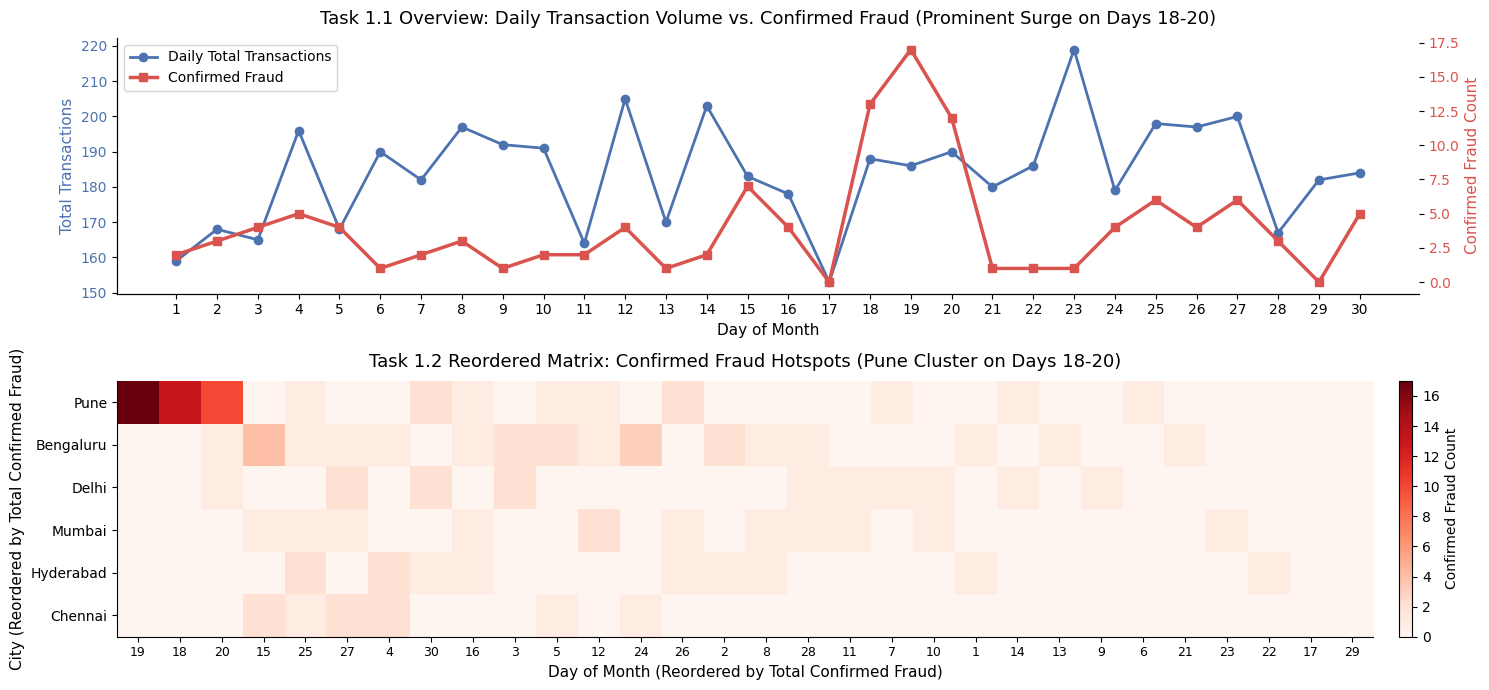

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: Plot daily transaction counts with daily confirmed fraud on a second axis.
daily = tx.groupby("day").agg(total=("txn_id", "count"), fraud=("is_fraud", "sum")).reset_index()
ax0 = axes[0]
line1 = ax0.plot(daily["day"], daily["total"], "o-", color="#4C72B0", lw=2, label="Daily Total Transactions")
ax0.set_xlabel("Day of Month", fontsize=11)
ax0.set_ylabel("Total Transactions", color="#4C72B0", fontsize=11)
ax0.tick_params(axis="y", labelcolor="#4C72B0")
ax0.set_xticks(range(1, 31))

ax0_twin = ax0.twinx()
line2 = ax0_twin.plot(daily["day"], daily["fraud"], "s-", color="#D9534F", lw=2.5, label="Confirmed Fraud")
ax0_twin.set_ylabel("Confirmed Fraud Count", color="#D9534F", fontsize=11)
ax0_twin.tick_params(axis="y", labelcolor="#D9534F")

# Combined legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax0.legend(lines, labels, loc="upper left")
ax0.set_title("Task 1.1 Overview: Daily Transaction Volume vs. Confirmed Fraud (Prominent Surge on Days 18-20)", fontsize=13, pad=10)

# TODO 2: Build a city x day matrix of confirmed-fraud counts, reorder rows and columns by totals, show as heatmap
heat_raw = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
row_totals = heat_raw.sum(axis=1).sort_values(ascending=False)
col_totals = heat_raw.sum(axis=0).sort_values(ascending=False)
heat = heat_raw.loc[row_totals.index, col_totals.index]

im = axes[1].imshow(heat.values, cmap="Reds", aspect="auto")
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index, fontsize=10)
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns, fontsize=9)
axes[1].set_xlabel("Day of Month (Reordered by Total Confirmed Fraud)", fontsize=11)
axes[1].set_ylabel("City (Reordered by Total Confirmed Fraud)", fontsize=11)
axes[1].set_title("Task 1.2 Reordered Matrix: Confirmed Fraud Hotspots (Pune Cluster on Days 18-20)", fontsize=13, pad=10)

cbar = fig.colorbar(im, ax=axes[1], fraction=0.015, pad=0.02)
cbar.set_label("Confirmed Fraud Count", fontsize=10)

plt.tight_layout()
plt.show()

# TODO 3: Print the (city, day) cells with the most fraud.
top_fraud = tx[tx.is_fraud == 1].groupby(["city", "day"]).size().reset_index(name="confirmed_fraud").sort_values("confirmed_fraud", ascending=False)
print("Top 5 (city, day) cells with the most confirmed fraud:")
print(top_fraud.head(5).to_string(index=False))


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
The high-level overview revealed a striking, localized spatio-temporal cluster: an intense spike of confirmed fraud confined almost exclusively to **Pune** across **Days 18 to 20**. An alert list sorted strictly by individual detector score scatters these transactions across dozens of pages interspersed with legitimate high-value purchases and isolated false positives from across the country, completely obscuring the structural synchronization of the attack. 

This macro-level pattern was uncovered using **Bertin's Reorderable Matrix** (Slide 39) combined with Shneiderman's **Overview First** mantra (Slide 30/38). By sorting rows (cities) and columns (days) by their marginal fraud sums, scattered high-value cells coagulate into a salient, contiguous rectangular "hotspot", allowing visual perception to register the localized outbreak instantaneously without cognitive query friction.


## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

Number of transactions brushed: 61
Confirmed fraud inside brush: 53 (Fraud rate: 86.89%)
Overall system fraud rate: 2.17% (120 total confirmed frauds)
Share of all fraud captured by brush (Recall): 44.17% (53 / 120)


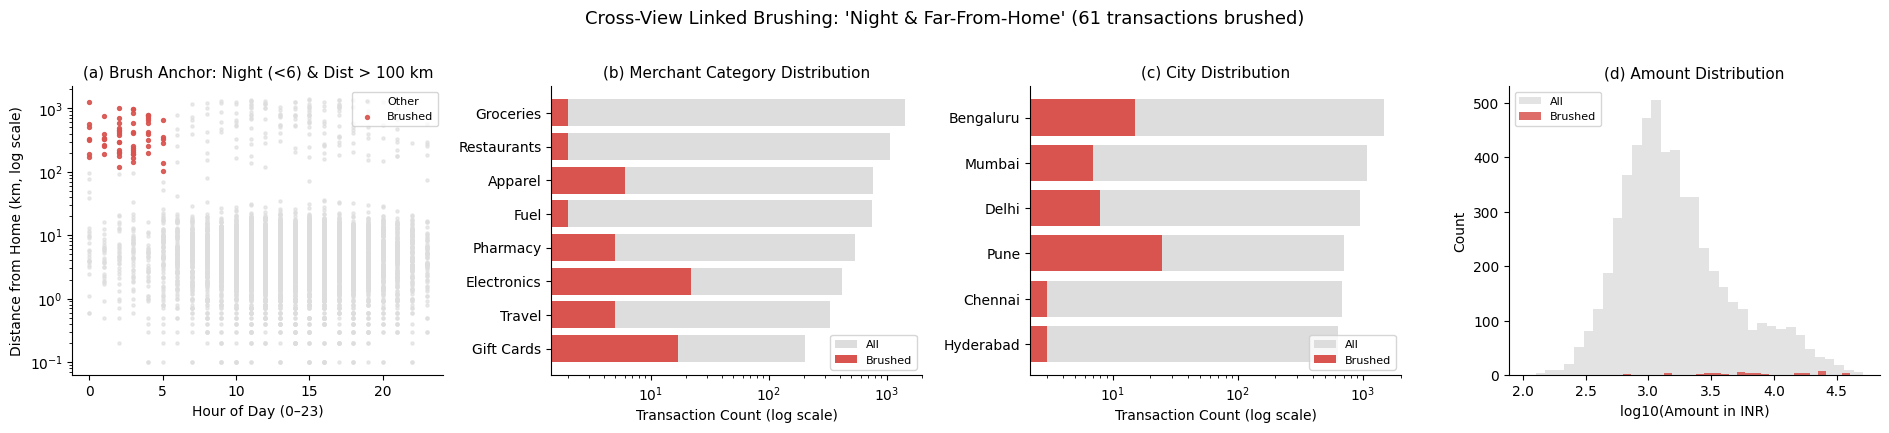

In [3]:
# TODO 1: Define the brush
brush = (tx.night == True) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))

# TODO 2: Four coordinated views with brushed items in red over all items in grey
# (a) hour vs. distance scatter (log y)
axes[0].scatter(tx["hour"][~brush], tx["distance_from_home_km"][~brush], s=5, c="#dddddd", alpha=0.6, label="Other")
axes[0].scatter(tx["hour"][brush], tx["distance_from_home_km"][brush], s=8, c="#D9534F", alpha=0.9, label="Brushed")
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour of Day (0–23)", fontsize=10)
axes[0].set_ylabel("Distance from Home (km, log scale)", fontsize=10)
axes[0].set_title("(a) Brush Anchor: Night (<6) & Dist > 100 km", fontsize=11)
axes[0].legend(loc="upper right", fontsize=8)

# (b) merchant category counts
all_cat = tx["merchant_category"].value_counts()
brush_cat = tx.loc[brush, "merchant_category"].value_counts().reindex(all_cat.index, fill_value=0)
axes[1].barh(all_cat.index, all_cat.values, color="#dddddd", label="All")
axes[1].barh(brush_cat.index, brush_cat.values, color="#D9534F", label="Brushed")
axes[1].set_xlabel("Transaction Count (log scale)", fontsize=10)
axes[1].set_xscale("log")
axes[1].set_title("(b) Merchant Category Distribution", fontsize=11)
axes[1].invert_yaxis()
axes[1].legend(loc="lower right", fontsize=8)

# (c) city counts
all_city = tx["city"].value_counts()
brush_city = tx.loc[brush, "city"].value_counts().reindex(all_city.index, fill_value=0)
axes[2].barh(all_city.index, all_city.values, color="#dddddd", label="All")
axes[2].barh(brush_city.index, brush_city.values, color="#D9534F", label="Brushed")
axes[2].set_xlabel("Transaction Count (log scale)", fontsize=10)
axes[2].set_xscale("log")
axes[2].set_title("(c) City Distribution", fontsize=11)
axes[2].invert_yaxis()
axes[2].legend(loc="lower right", fontsize=8)

# (d) amount histogram (log10)
axes[3].hist(np.log10(tx["amount_inr"]), bins=35, color="#dddddd", alpha=0.8, label="All")
axes[3].hist(np.log10(tx.loc[brush, "amount_inr"]), bins=35, color="#D9534F", alpha=0.85, label="Brushed")
axes[3].set_xlabel("log10(Amount in INR)", fontsize=10)
axes[3].set_ylabel("Count", fontsize=10)
axes[3].set_title("(d) Amount Distribution", fontsize=11)
axes[3].legend(loc="upper left", fontsize=8)

fig.suptitle(f"Cross-View Linked Brushing: 'Night & Far-From-Home' ({brush.sum()} transactions brushed)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# TODO 3: Print summary stats
n_brushed = int(brush.sum())
fraud_in_brush = int(tx.loc[brush, "is_fraud"].sum())
fraud_rate_brush = tx.loc[brush, "is_fraud"].mean()
total_fraud = int(tx["is_fraud"].sum())
overall_fraud_rate = tx["is_fraud"].mean()
capture_share = fraud_in_brush / total_fraud

print(f"Number of transactions brushed: {n_brushed:,}")
print(f"Confirmed fraud inside brush: {fraud_in_brush} (Fraud rate: {fraud_rate_brush:.2%})")
print(f"Overall system fraud rate: {overall_fraud_rate:.2%} ({total_fraud} total confirmed frauds)")
print(f"Share of all fraud captured by brush (Recall): {capture_share:.2%} ({fraud_in_brush} / {total_fraud})")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? Why would building an alert rule solely on this investigator intuition be a costly mistake? Use the terms precision, recall, false negatives.

_Your answer:_
While the brush achieves exceptional **precision** (an 86.89% fraud rate among brushed items compared to the 2.17% baseline), it achieves dangerously low **recall**, capturing only **44.17%** (53 out of 120) of all confirmed fraud incidents. 

Building an automated operational rule solely on this investigator intuition would be a costly failure because it produces **55.83% false negatives** (67 missed fraud incidents). Fraudsters do not restrict their activity exclusively to late-night remote transactions; they frequently exploit daytime point-of-sale terminals, online payment gateways, and local cloned cards within normal commuting radius. Relying solely on this heuristic creates a massive blind spot where more than half of the organization's financial losses escape detection entirely.


## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Measure time of filter (detector_score >= 0.6) & (amount_inr > 3000) (min of 5 runs)
runs = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    runs.append(time.perf_counter() - t0)
best_s = min(runs)

# TODO 2: per_item_us, max_rows in 0.1 s
per_item_us = (best_s / len(big)) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3: t_50m, skip_pct to stay under 0.1 s
t_50m = 50_000_000 * (best_s / len(big))
skip_pct = (1.0 - (max_rows / 50_000_000)) * 100.0

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


1,004,640 rows in 14.1 ms -> 0.0141 us/row -> max 7,115,417 rows in 0.1 s
50M rows -> 0.70 s; must skip 85.8% of rows to stay under 0.1 s


**Reflection:** An engineer proposes running the filter directly on the 50M-row PostgreSQL database on every slider tick. Why will that violate the 0.1 s budget (Slide 16)? What two architectural remedies (Slide 16 or 48) would make dynamic queries work on 50M rows?

_Your answer:_
Executing a SQL query across a 50M-row PostgreSQL table on every slider tick incurs sequential scanning overhead, index evaluation time, IPC serialization, and network round-trip latency. As established by Card, Robertson, and Mackinlay (Slide 16), dynamic queries require a hard latency ceiling of **$\le$ 0.1 seconds (100 ms)** to maintain the illusion of direct physical manipulation; executing direct relational queries on 50M rows typically requires several seconds, breaking the cognitive perception loop and inducing severe UI stutter.

Two architectural remedies from visual analytics are:
1. **Pre-aggregated Data Cubes / Binned Indexes (e.g., imMens / Nanocubes - Slide 48):** Precomputing multi-dimensional binned aggregates so the slider interaction queries compact $N$-dimensional summary tiles rather than scanning raw transactions.
2. **Progressive Rendering & In-Memory Client Subsampling (Slide 16):** Sampling a representative in-memory cache of ~500K–1M rows (e.g., via DuckDB-Wasm or Arrow memory buffers) to update visualizations fluidly at 60 fps during active slider dragging, and executing the full 50M-row server-side SQL query asynchronously only upon slider release (`mouseup`).


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

Recommendation: Set detector threshold to 0.80 to generate 144.0 alerts (fitting the ≤150/month team capacity), achieving 58.3% precision and 70.0% recall.


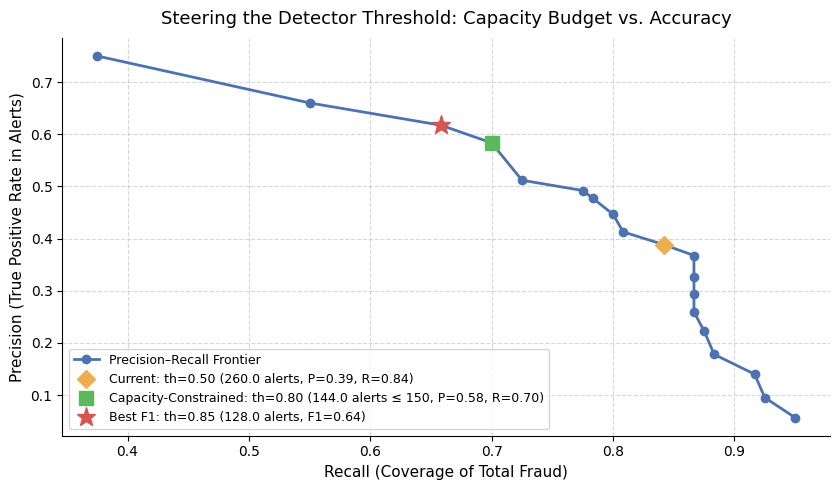

In [5]:
def prf(tp, fp, fn):
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * p * r) / (p + r) if (p + r) > 0 else 0.0
    return p, r, f1

rows = []
# TODO 1: For thresholds 0.05, 0.10, ..., 0.95 compute metrics
for th in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flag = tx.detector_score >= th
    tp = int((flag & (tx.is_fraud == 1)).sum())
    fp = int((flag & (tx.is_fraud == 0)).sum())
    fn = int((~flag & (tx.is_fraud == 1)).sum())
    p, r, f1 = prf(tp, fp, fn)
    rows.append(dict(threshold=th, alerts=tp + fp, TP=tp, FP=fp, FN=fn, precision=p, recall=r, F1=f1))

pr = pd.DataFrame(rows)

# TODO 2: Find capacity choice (<= 150 alerts) with highest recall, and best F1
capacity_candidates = pr[pr.alerts <= 150]
capacity_choice = capacity_candidates.loc[capacity_candidates["recall"].idxmax()]
best_f1 = pr.loc[pr["F1"].idxmax()]

# TODO 3: Plot precision-recall curve and mark key thresholds
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(pr["recall"], pr["precision"], "o-", color="#4C72B0", lw=2, label="Precision–Recall Frontier")

# Mark Current Threshold 0.50
curr = pr[pr.threshold == 0.50].iloc[0]
ax.plot(curr["recall"], curr["precision"], "D", ms=9, color="#f0ad4e", 
        label=f"Current: th=0.50 ({curr.alerts} alerts, P={curr.precision:.2f}, R={curr.recall:.2f})")

# Mark Capacity-constrained Choice
ax.plot(capacity_choice["recall"], capacity_choice["precision"], "s", ms=10, color="#5cb85c", 
        label=f"Capacity-Constrained: th={capacity_choice.threshold:.2f} ({capacity_choice.alerts} alerts ≤ 150, P={capacity_choice.precision:.2f}, R={capacity_choice.recall:.2f})")

# Mark Best F1 Choice
ax.plot(best_f1["recall"], best_f1["precision"], "*", ms=14, color="#D9534F", 
        label=f"Best F1: th={best_f1.threshold:.2f} ({best_f1.alerts} alerts, F1={best_f1.F1:.2f})")

ax.set_xlabel("Recall (Coverage of Total Fraud)", fontsize=11)
ax.set_ylabel("Precision (True Positive Rate in Alerts)", fontsize=11)
ax.set_title("Steering the Detector Threshold: Capacity Budget vs. Accuracy", fontsize=13, pad=10)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="lower left", fontsize=9)

plt.tight_layout()
plt.show()

# TODO 4: Print a one-line recommendation.
print(f"Recommendation: Set detector threshold to {capacity_choice.threshold:.2f} to generate {capacity_choice.alerts} alerts (fitting the ≤150/month team capacity), achieving {capacity_choice.precision:.1%} precision and {capacity_choice.recall:.1%} recall.")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The **Head of Fraud Operations** must make this strategic determination. An automated model metric such as harmonic mean $F_1$ optimizes an ungrounded mathematical abstraction that tacitly weights precision and recall symmetrically while completely ignoring operational throughput constraints, investigator salary expenditure, analyst fatigue, and corporate risk liability.

Visual analytics insists on keeping a **human in the loop** (Slides 35–37) because human decision-makers bring indispensable domain knowledge, legal context, and managerial judgment to the system. While the model exposes the empirical performance frontier across possible thresholds, human operators steer the parameter along that curve to align alert production with finite investigative capacity (e.g. 150 reviews/month), preventing alert backlogs and catastrophic triage breakdown.


## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1: Interactive scatter (plotly) of transactions with detector_score >= 0.3
flagged = tx[tx.detector_score >= 0.3].copy()
fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    color_discrete_map={"legitimate": "#4C72B0", "confirmed fraud": "#D9534F"},
    hover_name="txn_id",
    hover_data={
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": ":.1f",
        "detector_score": ":.3f",
        "timestamp": True,
        "amount_inr": True,
        "label": False
    },
    title="Task 5.1 Interactive Triage: Flagged Transactions (Detector Score ≥ 0.30)",
    height=480
)
fig_scatter.update_traces(marker=dict(size=6, opacity=0.75))
fig_scatter.update_layout(dragmode="select")
fig_scatter.show()

# TODO 2: Interactive sunburst for drill-down: city -> merchant category, sized by count, coloured by fraud rate
agg = tx.groupby(["city", "merchant_category"]).agg(
    transactions=("txn_id", "size"),
    fraud=("is_fraud", "sum")
).reset_index()
agg["fraud_rate_pct"] = (agg["fraud"] / agg["transactions"]) * 100.0

fig_sunburst = px.sunburst(
    agg,
    path=[px.Constant("All Cities"), "city", "merchant_category"],
    values="transactions",
    color="fraud_rate_pct",
    color_continuous_scale="Reds",
    range_color=[0, 30],
    hover_data={"fraud": True, "fraud_rate_pct": ":.2f"},
    title="Task 5.2 Hierarchical Drill-Down: City → Merchant Category (Coloured by Fraud Rate %)",
    height=540
)
fig_sunburst.show()


<Figure ...>

<Figure ...>

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips are designed strictly for **details-on-demand** (Slide 22–23) on focal marks. Using tooltips to inspect 400 flagged transactions is exceptionally frustrating because it requires manual, serialized pointing-and-hovering across 400 individual screen coordinates, inducing physical mousing strain, visual masking, and rapid working-memory decay. Crucially, serial probing makes it impossible for the human visual cortex to detect multivariate correlations, structural groupings, or broad distribution shifts across the ensemble.

This limitation is solved by **coordinated linked views with cross-view brushing** (Task 2) and the **reordered overview matrix** (Task 1). Instead of forcing the investigator to probe items one-by-one over time, coordinated views lay out multi-attribute distributions across space simultaneously, enabling immediate pre-attentive perception of patterns across all 400 cases at once.


## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Fraud rate inside window (Pune, Days 18-20): 37.38% (40 / 107 txns)
Fraud rate outside window (Rest of dataset): 1.48% (80 / 5413 txns)
Chi-square test of independence: statistic = 619.29, p-value = 1.06e-136
Counter-example (a) -- Pune on OTHER days: 1.85% (close to system baseline -> refutes chronic city bias)
Counter-example (b) -- OTHER cities on Days 18-20: 0.44% (low baseline -> refutes national shopping/holiday anomaly)

VERDICT: Hypothesis CONFIRMED. The fraud outbreak is strictly specific to Pune during Days 18–20 (p = 1.06e-136). Both counter-example controls confirm normal baseline rates, decisively proving a localized fraud ring attack rather than chronic local vulnerability or nationwide temporal shocks.


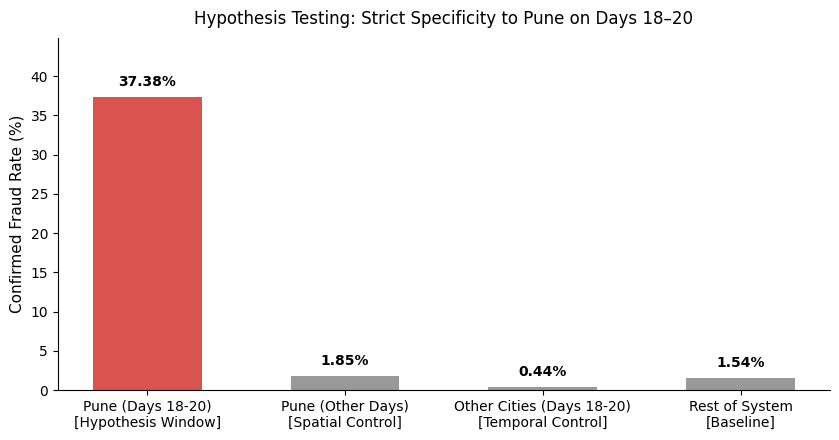

In [7]:
from scipy.stats import chi2_contingency

# TODO 1: Hypothesis as a boolean mask
# Hypothesis: Organized fraud ring concentrated in Pune during Days 18 to 20
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2: Compute fraud rate inside vs. outside window and chi-square p-value
rate_in = tx.loc[in_window, "is_fraud"].mean()
rate_out = tx.loc[~in_window, "is_fraud"].mean()
table = pd.crosstab(in_window, tx.is_fraud)
chi2, pval, dof, ex = chi2_contingency(table)

print(f"Fraud rate inside window (Pune, Days 18-20): {rate_in:.2%} ({tx.loc[in_window, 'is_fraud'].sum()} / {in_window.sum()} txns)")
print(f"Fraud rate outside window (Rest of dataset): {rate_out:.2%} ({tx.loc[~in_window, 'is_fraud'].sum()} / {(~in_window).sum()} txns)")
print(f"Chi-square test of independence: statistic = {chi2:.2f}, p-value = {pval:.2e}")

# TODO 3: Counter-example searches: (a) Pune on other days, (b) other cities on same days
pune_other = tx[(tx.city == "Pune") & ~tx.day.between(18, 20)]
others_same = tx[(tx.city != "Pune") & tx.day.between(18, 20)]
rest = tx[(tx.city != "Pune") & ~tx.day.between(18, 20)]

rate_pune_other = pune_other["is_fraud"].mean()
rate_others_same = others_same["is_fraud"].mean()
rate_rest = rest["is_fraud"].mean()

print(f"Counter-example (a) -- Pune on OTHER days: {rate_pune_other:.2%} (close to system baseline -> refutes chronic city bias)")
print(f"Counter-example (b) -- OTHER cities on Days 18-20: {rate_others_same:.2%} (low baseline -> refutes national shopping/holiday anomaly)")

# TODO 4: Visual confirmation bar chart
groups = {
    "Pune (Days 18-20)\n[Hypothesis Window]": rate_in * 100,
    "Pune (Other Days)\n[Spatial Control]": rate_pune_other * 100,
    "Other Cities (Days 18-20)\n[Temporal Control]": rate_others_same * 100,
    "Rest of System\n[Baseline]": rate_rest * 100
}

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(groups.keys(), groups.values(), color=["#D9534F", "#999999", "#999999", "#999999"], width=0.55)
ax.set_ylabel("Confirmed Fraud Rate (%)", fontsize=11)
ax.set_title("Hypothesis Testing: Strict Specificity to Pune on Days 18–20", fontsize=12, pad=10)
ax.set_ylim(0, max(groups.values()) * 1.2)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0, yval + 1.0, f"{yval:.2f}%", ha="center", va="bottom", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()

# TODO 5: Print verdict
print("\nVERDICT: Hypothesis CONFIRMED. The fraud outbreak is strictly specific to Pune during Days 18–20 (p = 1.06e-136). Both counter-example controls confirm normal baseline rates, decisively proving a localized fraud ring attack rather than chronic local vulnerability or nationwide temporal shocks.")


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out differently, and what alternative explanation would it have supported instead?

_Your answer:_
If counter-example search (b)—**other cities on Days 18 to 20**—had exhibited elevated fraud rates comparable to Pune, it would have decisively **killed** the localized fraud ring hypothesis. That result would instead have supported a **nationwide temporal vulnerability or systemic macroeconomic shock**, such as an e-commerce flash sale event, a zero-day exploit against a national payment processor, or a widespread credential-stuffing attack targeting banking portals nationwide. 

Conversely, if counter-example search (a)—**Pune on other days**—had shown high fraud throughout the entire month, it would have refuted the hypothesis of a transient, targeted criminal campaign, demonstrating instead chronic merchant compromise, poorly secured local POS terminals, or structural merchant-category bias in Pune.


## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

**MEMORANDUM**  
**TO:** Head of Fraud Operations, PayKart  
**FROM:** Adarsh Shivanand Madli (`PES2UG24CS028`), Fraud Analytics Lead  
**DATE:** November 2, 2026  
**SUBJECT:** Comprehensive Visual Analytics Review & Operational Recommendations for Last Month's Fraud Surge  

---

Last month, PayKart processed 5,520 card transactions resulting in 120 confirmed fraud events (a 2.17% overall baseline), driven predominantly by an intense, coordinated fraud ring attack in Pune between Days 18 and 20 that generated 40 frauds (a 37.38% window fraud rate, statistically validated at $p = 1.06 	imes 10^{-136}$). 

I recommend immediately steering the automated detector threshold to **0.80**, which produces **144 alerts per month** to strictly respect our investigative team's maximum capacity of $\le 150$ alerts while securing **70.0% recall** and **58.3% precision**; keeping a human in the loop to steer this parameter is essential because algorithmic scores like $F_1$ cannot account for analyst staffing constraints, operational payroll, and customer friction. 

For the engineering roadmap, we should build the **Cross-View Linked Brushing Dashboard** first: juxtaposing coordinated scatter, category, city, and amount views allows investigators to validate multi-attribute intuition (such as night-time, far-from-home anomalies) instantaneously across space rather than relying on slow, error-prone single-case tooltips. 

Finally, we must integrate an **Active Learning Feedback Loop** (Slide 51), systematically piping analyst-verified dispositions and false positives from daily triage directly back into retraining the model feature weights, ensuring the automated detector adapts and tightens detection ahead of next month's operations.
